<a href="https://colab.research.google.com/github/adhishmodi/customer-churn-prediction/blob/feature/milestone-4-model-evaluation/notebooks/04_model_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Prediction — Model Evaluation

Evaluate the frozen, cross-validation-selected model on the untouched 20% test split from the IBM Telco Customer Churn dataset.

**Evaluation rules**
- Recreate the exact stratified 80/20 split with random seed 42.
- Load the saved model pipeline from Milestone 3; do not retrain or tune it here.
- Keep the held-out test set out of threshold selection and every fitting step.
- Use the 0.50 threshold as the primary reference, then evaluate an additional threshold selected from training-only out-of-fold probabilities.
- Interpret metrics in the context of customer retention, not accuracy alone.

The selected pipeline contains both the fitted preprocessing transformer and classifier. Its preprocessing must be reused as saved.

## 1. Runtime setup and artifact loading

Run this notebook in the same Colab runtime as Model Training when possible. The raw dataset and generated model artifacts are intentionally excluded from GitHub. If they are not present, this section will ask you to upload them.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys

REPOSITORY_URL = "https://github.com/adhishmodi/customer-churn-prediction.git"
EXPECTED_CSV = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
MODEL_FILENAME = "best_model_candidate.joblib"
METADATA_FILENAME = "training_metadata.json"

current_dir = Path.cwd()
PROJECT_ROOT = next(
    (
        path for path in (current_dir, *current_dir.parents)
        if (path / "src" / "preprocess.py").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    PROJECT_ROOT = Path("/content/customer-churn-prediction")
    if not (PROJECT_ROOT / "src" / "preprocess.py").is_file():
        subprocess.run(
            ["git", "clone", "--depth", "1", "--branch", "main",
             REPOSITORY_URL, str(PROJECT_ROOT)],
            check=True,
        )

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import MODELS_DIR, RAW_DATA_PATH, REPORTS_DIR
from src.preprocess import clean_data, prepare_features_target, split_data
from src.train import FoldBalancedXGBClassifier, evaluate_model, get_cv_strategy

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = RAW_DATA_PATH
MODEL_PATH = MODELS_DIR / MODEL_FILENAME
METADATA_PATH = MODELS_DIR / METADATA_FILENAME

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_PATH}")
print(f"Model artifact: {MODEL_PATH}")
print(f"Training metadata: {METADATA_PATH}")

Project root: /content/customer-churn-prediction
Dataset path: /content/customer-churn-prediction/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv
Model artifact: /content/customer-churn-prediction/models/best_model_candidate.joblib
Training metadata: /content/customer-churn-prediction/models/training_metadata.json


In [2]:
missing_files = []
if not DATA_PATH.is_file():
    missing_files.append(("dataset", EXPECTED_CSV, DATA_PATH))
if not MODEL_PATH.is_file():
    missing_files.append(("model", MODEL_FILENAME, MODEL_PATH))
if not METADATA_PATH.is_file():
    missing_files.append(("metadata", METADATA_FILENAME, METADATA_PATH))

if missing_files:
    try:
        from google.colab import files
    except ImportError as exc:
        expected = "\\n".join(
            f"- {name}: {path}" for _, name, path in missing_files
        )
        raise FileNotFoundError(
            "Required project artifacts are missing. Place them at:\\n" + expected
        ) from exc

    def normalized_upload_name(filename):
        # Colab may append " (1)" when the same file is uploaded more than once.
        path = Path(filename).name
        stem, suffix = os.path.splitext(path)
        if stem.endswith(")") and " (" in stem:
            possible_number = stem.rsplit(" (", 1)[1][:-1]
            if possible_number.isdigit():
                stem = stem.rsplit(" (", 1)[0]
        return stem + suffix

    expected_by_name = {
        expected_name: (kind, destination)
        for kind, expected_name, destination in missing_files
    }
    print(
        "The following files are still required:",
        ", ".join(expected_by_name),
    )
    print(
        "Select the exact files from your Milestone 3 training run. "
        "Uploading the CSV again will not replace the model or metadata."
    )

    while expected_by_name:
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError(
                "Upload was cancelled. Still missing: "
                + ", ".join(expected_by_name)
            )

        for uploaded_name, file_bytes in uploaded.items():
            normalized_name = normalized_upload_name(uploaded_name)
            if normalized_name not in expected_by_name:
                print(
                    f"Ignored {uploaded_name!r}; it is not one of the required "
                    f"files: {', '.join(expected_by_name)}"
                )
                continue

            kind, destination = expected_by_name.pop(normalized_name)
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(file_bytes)
            print(f"Saved {kind}: {destination}")

        if expected_by_name:
            print(
                "Still missing:",
                ", ".join(expected_by_name),
                "— select the remaining file(s) in the next upload dialog.",
            )

    print("All missing files have been uploaded successfully.")

assert DATA_PATH.is_file(), f"Dataset not found: {DATA_PATH}"
assert MODEL_PATH.is_file(), f"Model artifact not found: {MODEL_PATH}"
assert METADATA_PATH.is_file(), f"Training metadata not found: {METADATA_PATH}"
print("Dataset, model artifact, and metadata are available.")

The following files are still required: WA_Fn-UseC_-Telco-Customer-Churn.csv, best_model_candidate.joblib, training_metadata.json
Select the exact files from your Milestone 3 training run. Uploading the CSV again will not replace the model or metadata.


Saving training_metadata.json to training_metadata.json
Saving best_model_candidate.joblib to best_model_candidate.joblib
Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Saved metadata: /content/customer-churn-prediction/models/training_metadata.json
Saved model: /content/customer-churn-prediction/models/best_model_candidate.joblib
Saved dataset: /content/customer-churn-prediction/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv
All missing files have been uploaded successfully.
Dataset, model artifact, and metadata are available.


## 2. Reconstruct and verify the original train/test split

The preprocessing milestone used a stratified 80/20 split with seed 42. We recreate it from the original CSV using the same cleaning and feature-target functions.

The test rows are not used to fit a transformer, train a model, select a model, or choose a threshold. The loaded pipeline already contains the preprocessing fitted on the training rows.

In [3]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display

raw_df = pd.read_csv(DATA_PATH)
cleaned_df = clean_data(raw_df)
X, y = prepare_features_target(cleaned_df)
X_train, X_test, y_train, y_test = split_data(X, y)

assert len(X_train) + len(X_test) == len(X)
assert X_train.index.intersection(X_test.index).empty
assert y_train.index.equals(X_train.index)
assert y_test.index.equals(X_test.index)
assert "customerID" not in X_train.columns
assert "Churn" not in X_train.columns
assert set(y_train.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

print(f"Dataset rows: {len(X):,}")
print(f"Training rows: {len(X_train):,}")
print(f"Held-out test rows: {len(X_test):,}")
print(f"Input feature count: {X_train.shape[1]}")
print(f"Training churn rate: {y_train.mean():.2%}")
print(f"Test churn rate: {y_test.mean():.2%}")

split_summary = pd.DataFrame({
    "customers": [
        len(y_train), int((y_train == 1).sum()),
        len(y_test), int((y_test == 1).sum()),
    ],
    "churn_rate": [
        (y_train == 1).mean(), (y_train == 1).mean(),
        (y_test == 1).mean(), (y_test == 1).mean(),
    ],
}, index=["Training set", "Training churn class", "Test set", "Test churn class"])
display(split_summary)

Dataset rows: 7,043
Training rows: 5,634
Held-out test rows: 1,409
Input feature count: 19
Training churn rate: 26.54%
Test churn rate: 26.54%


,customers,churn_rate
Training set,5634,0.265353
Training churn class,1495,0.265353
Test set,1409,0.265436
Test churn class,374,0.265436


In [4]:
# If preprocessing snapshots from Milestone 2 are present, verify their labels.
saved_y_test_path = PROJECT_ROOT / "data" / "processed" / "y_test.npy"
saved_y_train_path = PROJECT_ROOT / "data" / "processed" / "y_train.npy"

if saved_y_test_path.is_file():
    saved_y_test = np.load(saved_y_test_path)
    assert np.array_equal(saved_y_test, y_test.to_numpy()), (
        "Recreated test labels differ from the saved preprocessing snapshot. "
        "Confirm that the original CSV is unchanged."
    )
    print("Saved preprocessing y_test.npy matches the recreated test labels.")
else:
    print("No saved y_test.npy snapshot found; deterministic split checks passed.")

if saved_y_train_path.is_file():
    saved_y_train = np.load(saved_y_train_path)
    assert np.array_equal(saved_y_train, y_train.to_numpy())
    print("Saved preprocessing y_train.npy matches the recreated training labels.")

No saved y_test.npy snapshot found; deterministic split checks passed.


## 3. Load the frozen candidate and generate probabilities

The training metadata records which candidate won cross-validation. We verify that metadata and the saved artifact agree, then use the pipeline exactly as saved.

A probability is the model's estimated likelihood that a customer belongs to the churn class (class 1). A threshold converts that probability into a churn / no-churn prediction.

In [5]:
with METADATA_PATH.open("r", encoding="utf-8") as file:
    training_metadata = json.load(file)

selected_model_name = training_metadata.get("selected_model")
selection_metric = training_metadata.get("selection_metric")
if not selected_model_name:
    raise ValueError("Training metadata does not identify the selected model.")
if selection_metric != "cv_roc_auc_mean":
    raise ValueError(
        f"Unexpected selection metric in metadata: {selection_metric!r}"
    )
if training_metadata.get("test_set_evaluated") is not False:
    raise ValueError(
        "Training metadata indicates that the test set may already have been evaluated. "
        "Review the experiment history before treating this as a first final evaluation."
    )

model = joblib.load(MODEL_PATH)
if not hasattr(model, "named_steps"):
    raise TypeError("Expected a fitted scikit-learn Pipeline artifact.")
if not {"preprocessor", "classifier"}.issubset(model.named_steps):
    raise ValueError("Saved pipeline must contain preprocessor and classifier steps.")

preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]
if not hasattr(preprocessor, "transformers_"):
    raise ValueError("The saved preprocessing transformer is not fitted.")
if not hasattr(classifier, "classes_"):
    raise ValueError("The saved classifier is not fitted.")
if 1 not in list(classifier.classes_):
    raise ValueError("The saved classifier does not expose churn class 1.")

print(f"Selected model: {selected_model_name}")
print(f"Selection metric: {selection_metric}")
print(f"Recorded CV ROC-AUC: {training_metadata['cv_metrics'].get('cv_roc_auc_mean')}")
print(f"Pipeline classifier: {type(classifier).__name__}")
print("Saved preprocessing and classifier checks passed.")

Selected model: Tuned XGBoost
Selection metric: cv_roc_auc_mean
Recorded CV ROC-AUC: 0.8501421681616111
Pipeline classifier: FoldBalancedXGBClassifier
Saved preprocessing and classifier checks passed.


In [6]:
# The saved pipeline applies its already-fitted imputer, scaler, and encoder.
y_test_probability = model.predict_proba(X_test)[:, list(classifier.classes_).index(1)]
y_test_pred_default = (y_test_probability >= 0.50).astype(int)

assert len(y_test_probability) == len(y_test)
assert np.isfinite(y_test_probability).all()
assert ((y_test_probability >= 0) & (y_test_probability <= 1)).all()

print("Generated test probabilities:", len(y_test_probability))
print("Default classification threshold: 0.50")
display(pd.DataFrame({
    "actual_churn": y_test.to_numpy(),
    "predicted_churn": y_test_pred_default,
    "predicted_churn_probability": y_test_probability,
}).head())

Generated test probabilities: 1409
Default classification threshold: 0.50


,actual_churn,predicted_churn,predicted_churn_probability
0,0,0,0.051187
1,0,1,0.868614
2,0,0,0.165943
3,0,1,0.628820
4,0,0,0.040655


## 4. Classification metrics at the default threshold

We first report the conventional 0.50 threshold. Precision answers: "Of the customers flagged as likely to churn, how many actually churned?" Recall answers: "Of all customers who churned, how many did the model identify?"

F1-score balances precision and recall. Accuracy is included, but it should not be interpreted alone because non-churn customers are the majority class.

In [7]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

def calculate_classification_metrics(y_true, y_pred, y_probability):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_probability),
        "Average Precision": average_precision_score(y_true, y_probability),
    }

default_metrics = calculate_classification_metrics(
    y_test, y_test_pred_default, y_test_probability
)
default_metrics_df = pd.DataFrame.from_dict(
    default_metrics, orient="index", columns=["Test score"]
)
display(default_metrics_df.style.format("{:.4f}"))

,Test score
Accuracy,0.7402
Precision,0.5067
Recall,0.8102
F1-score,0.6235
ROC-AUC,0.8463
Average Precision,0.6660


## 5. Confusion matrix and classification report

The confusion matrix makes the model's errors concrete:

- **True positive (TP):** correctly identified a customer who churned.
- **True negative (TN):** correctly identified a customer who did not churn.
- **False positive (FP):** flagged a customer who did not churn.
- **False negative (FN):** failed to flag a customer who churned.

For a retention team, false negatives can mean missed opportunities to contact customers before they leave. False positives can mean spending retention resources on customers who would have stayed anyway.

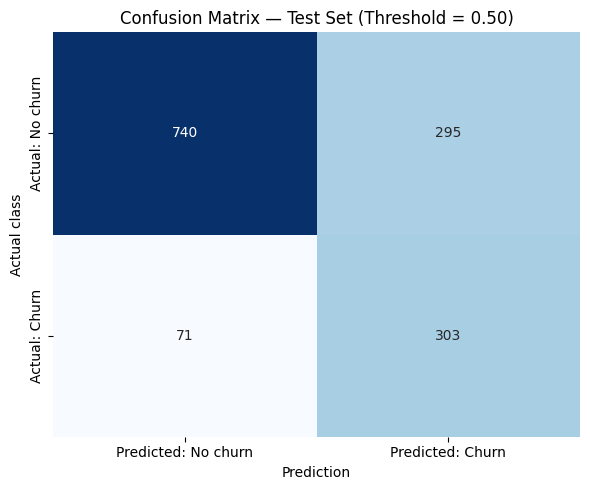

True negatives: 740
False positives: 295
False negatives: 71
True positives: 303


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm_default = confusion_matrix(y_test, y_test_pred_default, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm_default, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Predicted: No churn", "Predicted: Churn"],
    yticklabels=["Actual: No churn", "Actual: Churn"],
    ax=ax,
)
ax.set_title("Confusion Matrix — Test Set (Threshold = 0.50)")
ax.set_xlabel("Prediction")
ax.set_ylabel("Actual class")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_default.ravel()
print(f"True negatives: {tn:,}")
print(f"False positives: {fp:,}")
print(f"False negatives: {fn:,}")
print(f"True positives: {tp:,}")

In [9]:
print(classification_report(
    y_test,
    y_test_pred_default,
    labels=[0, 1],
    target_names=["No churn (0)", "Churn (1)"],
    digits=4,
    zero_division=0,
))

              precision    recall  f1-score   support

No churn (0)     0.9125    0.7150    0.8017      1035
   Churn (1)     0.5067    0.8102    0.6235       374

    accuracy                         0.7402      1409
   macro avg     0.7096    0.7626    0.7126      1409
weighted avg     0.8047    0.7402    0.7544      1409



## 6. ROC curve and ROC-AUC

The ROC curve shows the trade-off between the true-positive rate (recall) and false-positive rate at different probability thresholds. ROC-AUC summarizes how well the model ranks churners above non-churners.

A value near 0.5 indicates weak discrimination; a value closer to 1.0 indicates stronger discrimination. ROC-AUC evaluates ranking quality and does not choose an operating threshold for the business.

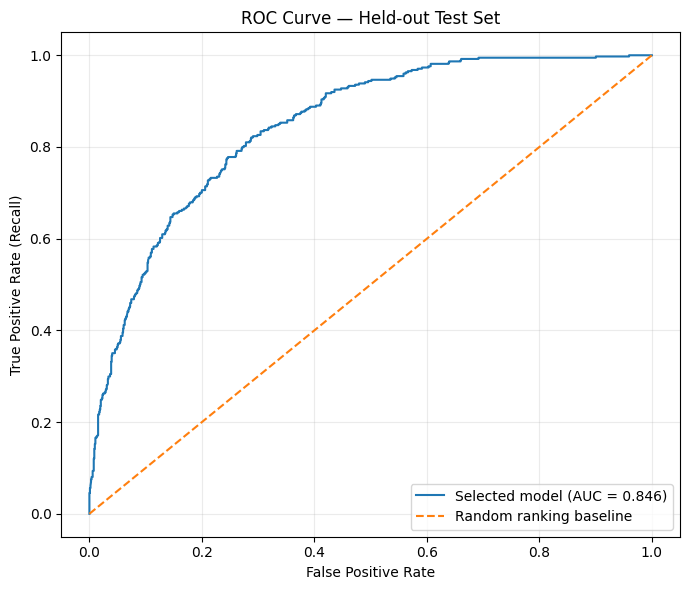

Test ROC-AUC: 0.8463
Recorded mean CV ROC-AUC: 0.8501


In [10]:
from sklearn.metrics import RocCurveDisplay, roc_curve

test_roc_auc = roc_auc_score(y_test, y_test_probability)
fpr, tpr, roc_thresholds = roc_curve(y_test, y_test_probability)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, label=f"Selected model (AUC = {test_roc_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random ranking baseline")
ax.set_title("ROC Curve — Held-out Test Set")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Test ROC-AUC: {test_roc_auc:.4f}")
print(
    "Recorded mean CV ROC-AUC:",
    f"{training_metadata['cv_metrics'].get('cv_roc_auc_mean', float('nan')):.4f}",
)

## 7. Precision-recall curve and Average Precision

The precision-recall curve focuses on the positive class (customers who churn). This is useful because churn is the minority class and the business is often interested in finding likely churners.

Average Precision summarizes the precision-recall curve. It is not the same as ROC-AUC, and it should be interpreted relative to the churn prevalence in the test set.

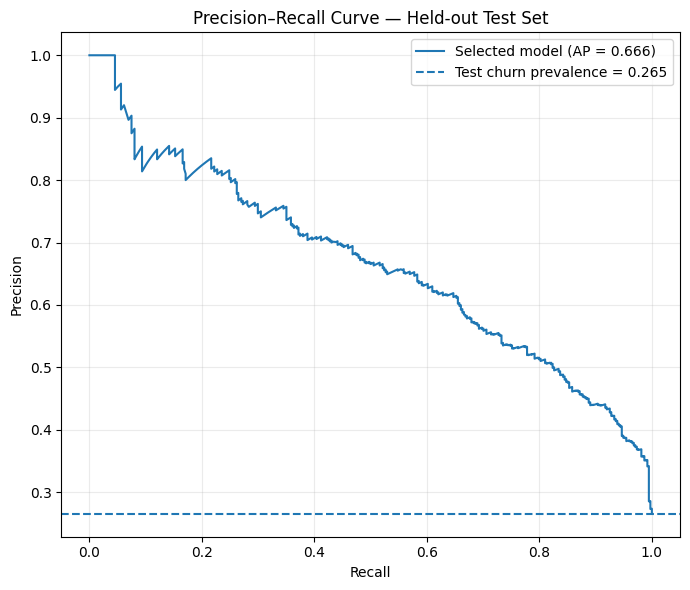

Test Average Precision: 0.6660
Test churn prevalence baseline: 0.2654


In [11]:
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score, precision_recall_curve

test_average_precision = average_precision_score(y_test, y_test_probability)
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_test, y_test_probability
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(
    pr_recall, pr_precision,
    label=f"Selected model (AP = {test_average_precision:.3f})",
)
ax.axhline(
    y=float(y_test.mean()), linestyle="--",
    label=f"Test churn prevalence = {y_test.mean():.3f}",
)
ax.set_title("Precision–Recall Curve — Held-out Test Set")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(loc="best")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Test Average Precision: {test_average_precision:.4f}")
print(f"Test churn prevalence baseline: {y_test.mean():.4f}")

## 8. Threshold selection and business trade-offs

The default 0.50 threshold is a reference, not automatically the best retention policy. A lower threshold usually identifies more potential churners (higher recall) but may also create more false alarms (lower precision).

To avoid using the held-out test set to choose a threshold, we generate out-of-fold (OOF) probabilities using only the training split and the already-selected model configuration. Each training row receives a probability from a model that did not train on that row.

We choose the threshold that maximizes training-only OOF F1-score. This is a transparent statistical demonstration, not a claim that F1 maximization is the optimal financial policy. A real retention policy should incorporate contact costs, offer costs, and the value of retaining each customer.

In [12]:
from sklearn.model_selection import cross_val_predict

# OOF predictions use training rows only; preprocessing is refitted inside each CV fold.
oof_probability = cross_val_predict(
    model,
    X_train,
    y_train,
    cv=get_cv_strategy(),
    method="predict_proba",
    n_jobs=1,
)[:, list(classifier.classes_).index(1)]

assert len(oof_probability) == len(y_train)
assert np.isfinite(oof_probability).all()
assert ((oof_probability >= 0) & (oof_probability <= 1)).all()

oof_precision, oof_recall, oof_thresholds = precision_recall_curve(
    y_train, oof_probability
)
oof_f1 = (
    2 * oof_precision[:-1] * oof_recall[:-1]
    / (oof_precision[:-1] + oof_recall[:-1] + 1e-12)
)
best_oof_index = int(np.nanargmax(oof_f1))
selected_threshold = float(oof_thresholds[best_oof_index])

print(f"Training-only OOF threshold selected by F1: {selected_threshold:.3f}")
print(f"OOF precision at selected threshold: {oof_precision[best_oof_index]:.4f}")
print(f"OOF recall at selected threshold: {oof_recall[best_oof_index]:.4f}")
print(f"OOF F1 at selected threshold: {oof_f1[best_oof_index]:.4f}")
print("The test labels were not used to select this threshold.")

Training-only OOF threshold selected by F1: 0.530
OOF precision at selected threshold: 0.5362
OOF recall at selected threshold: 0.7873
OOF F1 at selected threshold: 0.6379
The test labels were not used to select this threshold.


,threshold,precision,recall,f1,predicted_churners
0,0.10,0.3429,0.9920,0.5096,1082
1,0.15,0.3683,0.9759,0.5348,991
2,0.20,0.3864,0.9545,0.5501,924
3,0.25,0.4100,0.9385,0.5707,856
4,0.30,0.4349,0.9198,0.5906,791
5,0.35,0.4491,0.8850,0.5959,737
6,0.40,0.4679,0.8583,0.6057,686
7,0.45,0.4883,0.8369,0.6167,641
8,0.50,0.5067,0.8102,0.6235,598
9,0.55,0.5332,0.7727,0.6310,542


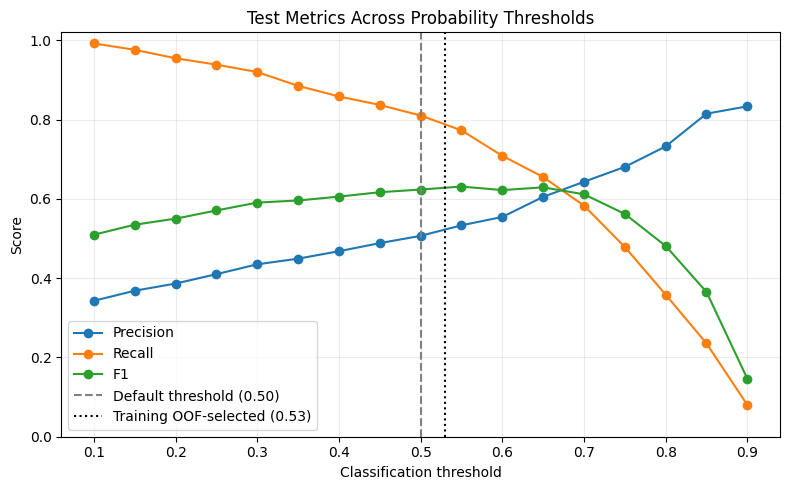

In [13]:
thresholds_to_compare = np.round(np.arange(0.10, 0.91, 0.05), 2)
threshold_rows = []

for threshold in thresholds_to_compare:
    predictions = (y_test_probability >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
        "predicted_churners": int(predictions.sum()),
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for metric in ["precision", "recall", "f1"]:
    ax.plot(
        threshold_results["threshold"],
        threshold_results[metric],
        marker="o",
        label=metric.capitalize(),
    )
ax.axvline(0.50, color="gray", linestyle="--", label="Default threshold (0.50)")
ax.axvline(
    selected_threshold, color="black", linestyle=":",
    label=f"Training OOF-selected ({selected_threshold:.2f})",
)
ax.set_title("Test Metrics Across Probability Thresholds")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.02)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [14]:
y_test_pred_selected = (y_test_probability >= selected_threshold).astype(int)
selected_threshold_metrics = calculate_classification_metrics(
    y_test, y_test_pred_selected, y_test_probability
)

threshold_comparison = pd.DataFrame(
    [default_metrics, selected_threshold_metrics],
    index=["Default threshold (0.50)", f"OOF-selected threshold ({selected_threshold:.3f})"],
)
display(threshold_comparison.T.round(4))

selected_cm = confusion_matrix(y_test, y_test_pred_selected, labels=[0, 1])
tn_s, fp_s, fn_s, tp_s = selected_cm.ravel()
print(
    f"At the OOF-selected threshold, the model flags {int(y_test_pred_selected.sum()):,} "
    f"test customers as potential churners."
)
print(f"False negatives: {fn_s:,} | False positives: {fp_s:,}")
print(
    "Threshold choice must ultimately reflect the company's retention capacity "
    "and the relative costs of missed churners and unnecessary offers."
)

,Default threshold (0.50),OOF-selected threshold (0.530)
Accuracy,0.7402,0.7509
Precision,0.5067,0.5202
Recall,0.8102,0.7914
F1-score,0.6235,0.6278
ROC-AUC,0.8463,0.8463
Average Precision,0.6660,0.6660


At the OOF-selected threshold, the model flags 569 test customers as potential churners.
False negatives: 78 | False positives: 273
Threshold choice must ultimately reflect the company's retention capacity and the relative costs of missed churners and unnecessary offers.


## 9. Overfitting checks and feature importance

### Generalization check

We compare in-sample training performance, held-out test performance, and the cross-validation summary already produced during training. Training scores are optimistic because the fitted model has seen those rows; they are included only as a diagnostic. The CV mean and untouched test results provide stronger evidence about generalization.

### Feature importance

For the selected XGBoost model, feature importance describes how much the fitted trees used each transformed input feature. It is a model-specific measure of predictive contribution, not proof that a feature causes churn.

In [15]:
# In-sample scores are diagnostic and should not be treated as unbiased estimates.
y_train_probability = model.predict_proba(X_train)[:, list(classifier.classes_).index(1)]
y_train_pred = (y_train_probability >= 0.50).astype(int)

train_metrics = calculate_classification_metrics(
    y_train, y_train_pred, y_train_probability
)
generalization_comparison = pd.DataFrame(
    [train_metrics, default_metrics],
    index=["Training (in-sample, threshold 0.50)", "Held-out test (threshold 0.50)"],
)
display(generalization_comparison.T.round(4))

cv_metrics = training_metadata.get("cv_metrics", {})
generalization_summary = pd.DataFrame({
    "cross_validation_mean": {
        "ROC-AUC": cv_metrics.get("cv_roc_auc_mean"),
        "Average Precision": cv_metrics.get("cv_average_precision_mean"),
        "Precision": cv_metrics.get("cv_precision_mean"),
        "Recall": cv_metrics.get("cv_recall_mean"),
        "F1-score": cv_metrics.get("cv_f1_mean"),
        "Accuracy": cv_metrics.get("cv_accuracy_mean"),
    },
    "cross_validation_std": {
        "ROC-AUC": cv_metrics.get("cv_roc_auc_std"),
        "Average Precision": cv_metrics.get("cv_average_precision_std"),
        "Precision": cv_metrics.get("cv_precision_std"),
        "Recall": cv_metrics.get("cv_recall_std"),
        "F1-score": cv_metrics.get("cv_f1_std"),
        "Accuracy": cv_metrics.get("cv_accuracy_std"),
    },
    "held_out_test": default_metrics,
})
display(generalization_summary.round(4))

,"Training (in-sample, threshold 0.50)",Held-out test (threshold 0.50)
Accuracy,0.7611,0.7402
Precision,0.5317,0.5067
Recall,0.8355,0.8102
F1-score,0.6498,0.6235
ROC-AUC,0.8668,0.8463
Average Precision,0.6977,0.6660


,cross_validation_mean,cross_validation_std,held_out_test
ROC-AUC,0.8501,0.0119,0.8463
Average Precision,0.6694,0.0210,0.6660
Precision,0.5195,0.0171,0.5067
Recall,0.8120,0.0252,0.8102
F1-score,0.6335,0.0186,0.6235
Accuracy,0.7506,0.0137,0.7402


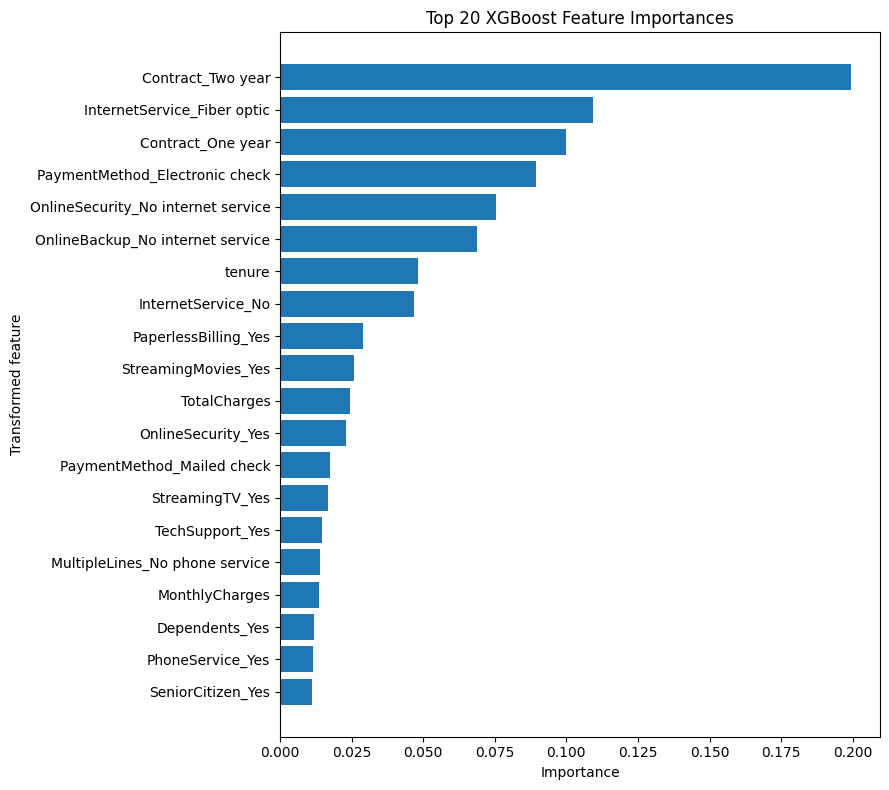

,feature,importance
0,Contract_Two year,0.19955
1,InternetService_Fiber optic,0.10947
2,Contract_One year,0.09983
3,PaymentMethod_Electronic check,0.08926
4,OnlineSecurity_No internet service,0.07529
5,OnlineBackup_No internet service,0.06868
6,tenure,0.04809
7,InternetService_No,0.04677
8,PaperlessBilling_Yes,0.02902
9,StreamingMovies_Yes,0.02571


In [16]:
# Inspect the fitted classifier's feature importance and match it to pipeline output names.
if hasattr(classifier, "estimator_") and hasattr(classifier.estimator_, "feature_importances_"):
    importance_values = classifier.estimator_.feature_importances_
elif hasattr(classifier, "feature_importances_"):
    importance_values = classifier.feature_importances_
else:
    raise AttributeError(
        "The selected classifier does not expose feature_importances_. "
        "Use a model-appropriate explainability method instead."
    )

transformed_feature_names = preprocessor.get_feature_names_out()
assert len(transformed_feature_names) == len(importance_values), (
    "Feature names and importance values have different lengths."
)

feature_importance = pd.DataFrame({
    "feature": transformed_feature_names,
    "importance": importance_values,
}).sort_values("importance", ascending=False).reset_index(drop=True)

top_features = feature_importance.head(20).sort_values("importance")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top_features["feature"], top_features["importance"])
ax.set_title("Top 20 XGBoost Feature Importances")
ax.set_xlabel("Importance")
ax.set_ylabel("Transformed feature")
plt.tight_layout()
plt.show()

display(feature_importance.head(20).round(5))

## 10. Final evaluation summary and business interpretation

The final report uses the default 0.50 threshold as the primary reference and separately reports the test results at the threshold selected using training-only OOF predictions.

Do not interpret feature importance as causation. The dataset is historical and observational; it does not show whether a particular retention offer would prevent an individual customer from churning.

Potential business use: rank customers by predicted churn probability so a retention team can prioritize outreach. Before deployment, the company should test interventions, estimate the costs of contact and discounts, and monitor model performance over time.

In [17]:
final_summary = pd.DataFrame({
    "metric": list(default_metrics.keys()),
    "test_score_at_0_50": list(default_metrics.values()),
})
cv_metric_lookup = {
    "Accuracy": "cv_accuracy_mean",
    "Precision": "cv_precision_mean",
    "Recall": "cv_recall_mean",
    "F1-score": "cv_f1_mean",
    "ROC-AUC": "cv_roc_auc_mean",
    "Average Precision": "cv_average_precision_mean",
}
final_summary["cv_mean"] = [
    cv_metrics.get(cv_metric_lookup[metric])
    for metric in final_summary["metric"]
]
display(final_summary.round(4))

print(f"Selected candidate: {selected_model_name}")
print(f"CV selection metric: {selection_metric}")
print(f"Recorded CV ROC-AUC: {cv_metrics.get('cv_roc_auc_mean', float('nan')):.4f}")
print(f"Held-out test ROC-AUC: {default_metrics['ROC-AUC']:.4f}")
print(f"Held-out test Average Precision: {default_metrics['Average Precision']:.4f}")
print(f"Default threshold: 0.50")
print(f"Training-only OOF-selected threshold: {selected_threshold:.3f}")

,metric,test_score_at_0_50,cv_mean
0,Accuracy,0.7402,0.7506
1,Precision,0.5067,0.5195
2,Recall,0.8102,0.8120
3,F1-score,0.6235,0.6335
4,ROC-AUC,0.8463,0.8501
5,Average Precision,0.6660,0.6694


Selected candidate: Tuned XGBoost
CV selection metric: cv_roc_auc_mean
Recorded CV ROC-AUC: 0.8501
Held-out test ROC-AUC: 0.8463
Held-out test Average Precision: 0.6660
Default threshold: 0.50
Training-only OOF-selected threshold: 0.530


In [18]:
# Save compact evaluation outputs locally; generated reports are ignored by Git.
metrics_output = pd.DataFrame([
    {"threshold_strategy": "default_0.50", "threshold": 0.50, **default_metrics},
    {
        "threshold_strategy": "training_oof_max_f1",
        "threshold": selected_threshold,
        **selected_threshold_metrics,
    },
])
metrics_path = REPORTS_DIR / "test_evaluation_metrics.csv"
importance_path = REPORTS_DIR / "feature_importance.csv"
threshold_path = REPORTS_DIR / "threshold_analysis.csv"

metrics_output.to_csv(metrics_path, index=False)
feature_importance.to_csv(importance_path, index=False)
threshold_results.to_csv(threshold_path, index=False)

print(f"Saved test metrics: {metrics_path}")
print(f"Saved feature importance: {importance_path}")
print(f"Saved threshold analysis: {threshold_path}")

Saved test metrics: /content/customer-churn-prediction/reports/test_evaluation_metrics.csv
Saved feature importance: /content/customer-churn-prediction/reports/feature_importance.csv
Saved threshold analysis: /content/customer-churn-prediction/reports/threshold_analysis.csv


## Final checks and conclusion

Before considering this milestone complete, confirm that:
- The original dataset and exact split were reconstructed.
- The loaded model is the CV-selected saved pipeline.
- The test set was not used for fitting, model selection, or threshold selection.
- Test predictions and probabilities have the expected shape and valid values.
- The training-only OOF procedure selected the additional threshold.
- Evaluation metrics and feature importance reports were saved.

The results in this notebook are generated from the artifacts and dataset available at runtime. Do not copy example metrics from documentation or another run into the report.

In [19]:
assert len(y_test_pred_default) == len(y_test)
assert len(y_test_pred_selected) == len(y_test)
assert np.isfinite(list(default_metrics.values())).all()
assert all(0.0 <= value <= 1.0 for value in default_metrics.values())
assert 0.0 <= selected_threshold <= 1.0
assert len(feature_importance) == len(transformed_feature_names)
assert metrics_path.is_file() and importance_path.is_file() and threshold_path.is_file()

print("All final evaluation assertions passed.")
print(f"Test rows evaluated: {len(y_test):,}")
print(f"Test churn prevalence: {y_test.mean():.2%}")
print(f"Primary test ROC-AUC: {default_metrics['ROC-AUC']:.4f}")
print(f"Primary test F1-score: {default_metrics['F1-score']:.4f}")
print("Milestone 4 evaluation completed.")

All final evaluation assertions passed.
Test rows evaluated: 1,409
Test churn prevalence: 26.54%
Primary test ROC-AUC: 0.8463
Primary test F1-score: 0.6235
Milestone 4 evaluation completed.
